# Baseline 3 — Christian-repository plain VQ-VAE-2, WS2 shared100

This notebook preserves the exact architecture, loss, batch 8, Adam at 1e-4, constant LR,
float32 computation and image geometry of your completed50-epoch baseline3.
It changes the **maximum** to100 epochs and adds the shared normal-only stopping policy:
patience10, meaningful relative loss improvement0.001, numerical absolute floor1e-8.
The selected checkpoint is independently the absolute lowest normal-selection MSE.
There is no smoke mode and no selection using test masks.

**Two valid starts:** leave both resume inputs blank for a new run, or attach the full
original50-epoch output folder and set `LEGACY_RUN_DIR`. The importer verifies the data,
source, settings, best/last checkpoint identities and all50 validation rows. It resumes
the optimizer at epoch51 and replays the new stopping rule. It rejects a trajectory
that should already have stopped. A later shared100 session uses `RESUME_DIR` instead.
The compact report ZIP does **not** contain `last.pt`; keep the full Kaggle output folder.

The previous0.335093 result stays an archived50-epoch result. This run creates a separate
result, which may improve or decline.100 epochs is an experimental cap, not a guarantee
of publication quality. Describe this as the Christian-repository VQ-VAE-2 variant;
it is not an assertion that every training detail of the original VQ-VAE-2 paper is reproduced.


In [1]:
from pathlib import Path

candidates = []

for config_file in Path("/kaggle/input").rglob("config.json"):
    folder = config_file.parent
    if all((folder / name).is_file()
           for name in ("config.json", "last.pt", "best.pt")):
        candidates.append(folder)
        print("Recovery folder:", folder)

if not candidates:
    print("No complete recovery folder found. Check the attached old output.")

Recovery folder: /kaggle/input/models/shuvroahmedimaging/your-old-vq-output/pytorch/default/1/VQVAE2_baseline_3_50


In [2]:
import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib
from pathlib import Path
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import (gaussian_filter, generate_binary_structure,
    binary_closing, binary_opening, binary_fill_holes, label)
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

# Full experiment only. No smoke setting.
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/VQVAE2_baseline_3_shared100')
# Normally leave blank. If multiple copies of WS2 are attached, set all four.
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''
# Optional previous output directory containing config.json, last.pt, best.pt.
RESUME_DIR = ''  # A previous shared100 output folder, including best.pt and last.pt.
LEGACY_RUN_DIR = '/kaggle/input/models/shuvroahmedimaging/your-old-vq-output/pytorch/default/1/VQVAE2_baseline_3_50'  # The completed ORIGINAL50-epoch baseline3 output folder.
MODEL_LABEL = 'Christian-repository plain VQ-VAE-2'
MAX_EPOCHS = 100
PATIENCE = 10
STOP_REL_DELTA = 0.001
STOP_ABS_FLOOR = 1e-8
SESSION_HOURS = 9.0
SAVE_BUFFER_SECONDS = 300.0
SESSION_START = time.monotonic()

class SessionPause(RuntimeError): pass

def check_session(required_seconds=0.):
    if time.monotonic()-SESSION_START+required_seconds+SAVE_BUFFER_SECONDS >= SESSION_HOURS*3600:
        raise SessionPause('Session time guard: stopped safely before the next complete operation.')
SEED = 1337
EPOCHS = MAX_EPOCHS
BATCH = 8
WORKERS = 2
SIZE = 256
LR, WEIGHT_DECAY = 1e-4, 0.0
VALIDATE_EVERY = 1
FPRS = (0.005, 0.01, 0.02, 0.05, 0.10)
SCORES = ('shared_mae', 'squared_error')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Enable a Kaggle GPU before running this full experiment.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
seed_all(SEED)

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()
def write_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False)); tmp.replace(path)
def save_pt(obj, path):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    torch.save(obj, tmp); tmp.replace(path)
def load_pt(path):
    return torch.load(path, map_location=DEVICE, weights_only=True)

def report_zip():
    destination = Path('/kaggle/working/VQVAE2_baseline_3_shared100_report.zip')
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if p.is_file() and '_cache' not in p.relative_to(RUN).parts and p.suffix in {'.json','.csv','.png','.txt','.py'}:
                z.write(p, p.relative_to(RUN))
    return destination
print('Full plain VQ-VAE-2 experiment: maximum', EPOCHS, 'epochs;', torch.cuda.get_device_name(0))


Full plain VQ-VAE-2 experiment: maximum 100 epochs; Tesla T4


## Inputs and exact split

Attach the same WS2 dataset used for the preceding runs. Expected folders are
`training/after`, `validation/after`, `images/before` and `masks/before`.
The notebook embeds the exact saved split:3,829 normal training images,
521 normal selection,128 calibration,234 audit and496 test images.
It verifies membership, byte hashes, and separation of normal validation videos.
If multiple WS2 copies are attached, set all four root overrides.

For a continuation, the additional inputs are `config.json`, `last.pt`, `best.pt`
inside the complete old output directory. Original weights remain untouched.
No test masks are decoded until the selected model and normal thresholds are locked.


In [3]:
# Exact record order from qmem_experiment8/20260921_202543_2328f4/splits.json
REFERENCE = json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')))
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
assert {k:len(v) for k,v in REFERENCE.items()} == EXPECTED
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set the root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training' and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images' and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Read names only here; labels are decoded after thresholds are locked.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique([p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)
config = dict(implementation='christian_repository_plain_VQVAE2_v1', seed=SEED, epochs=EPOCHS,
    batch=BATCH, size=SIZE, training_samples="whole 256x256 images", hidden_channels=128, embedding_dim=64, num_embeddings=1024, decay=.99, commitment_cost=.25,
    lr=LR, weight_decay=WEIGHT_DECAY, validation_every=VALIDATE_EVERY,
    checkpoint_selection='lowest normal-selection full-image reconstruction MSE', loss='mean RGB reconstruction MSE + top commitment + bottom commitment', model_source_sha256='00ff2d9cfc71b47f94fa5f923bb0f0f8d70ec0ef10a64c524605dd4c39d05e80', repository_commit='ba0b971b86fab7a9c53df4b09847b925c2cee262',
    initialization='PyTorch defaults', optimizer='Adam, betas=(0.9,0.999), eps=1e-8, foreach=False',
    precision='float32, no AMP or TF32', scheduler='none',
    score_names=list(SCORES), sigma=1, fpr_targets=list(FPRS),
    split_sha256=digest(REFERENCE), data_sha256=digest(hashes),
    historical='all normal-validation pixels, Q3+4*IQR',
    masks='PIL bilinear resize 256, grayscale/255 > 0.5', empty_union_iou=1.0)
config.update(maximum_epochs=MAX_EPOCHS,patience=PATIENCE,stop_relative_delta=STOP_REL_DELTA,
    stop_absolute_floor=STOP_ABS_FLOOR,early_stopping_metric='normal-selection full-image MSE',
    best_checkpoint_rule='absolute minimum normal-selection MSE; separate from stopping anchor',
    benchmark_protocol='shared100_v1',training_sample_unit='whole 256x256 image',
    score_selection='shared_mae primary; squared_error prespecified secondary',
    session_hours=SESSION_HOURS)
if RESUME_DIR and LEGACY_RUN_DIR: raise ValueError('Set only one resume input')
RUN.mkdir(parents=True,exist_ok=True)
if (RUN/'config.json').exists():
    if json.loads((RUN/'config.json').read_text())!=config: raise RuntimeError('Existing output belongs to different settings/data. Use a new RUN directory.')
else:
    if (RUN/'last.pt').exists(): raise RuntimeError('Checkpoint without config.json.')
    write_json(RUN/'config.json',config)
write_json(RUN/'splits.json',splits)
write_json(RUN/'input_hashes.json',hashes)
write_json(RUN/'environment.json',dict(torch=str(torch.__version__),numpy=np.__version__,python=sys.version,gpu=torch.cuda.get_device_name(0)))
CACHE = RUN/'_cache'; CACHE.mkdir(exist_ok=True)
print('Exact split verified:', {k:len(v) for k,v in splits.items()})


Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split verified: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}


## Model and normal images

The bottom encoder produces64×64 codes and the top encoder16×16 codes.
Top conditioning and quantized bottom codes feed the RGB decoder. Codebooks are
updated by EMA only during training. The network minimizes RGB MSE plus the
top and bottom commitment losses; no Christian four-loss or QMEM term is added here.
This is the plain baseline, with exactly the original source classes.

Total parameters include EMA embeddings. The report separately identifies network
parameters updated by backpropagation and codebook entries updated by EMA.
All full training frames are used, including the last short batch.


In [4]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.uint8,copy=True)
def cache_images(role):
    path=CACHE/f'images_{role}.npy'; shape=(len(splits[role]),SIZE,SIZE,3)
    if not path.exists():
        temp=CACHE/f'images_{role}.tmp.npy'
        a=np.lib.format.open_memmap(temp,mode='w+',dtype=np.uint8,shape=shape)
        for i,r in enumerate(tqdm(splits[role],desc='Resize '+role)): a[i]=read_rgb(r['path'])
        a.flush(); del a; temp.replace(path)
    a=np.load(path,mmap_mode='r')
    assert a.shape==shape and a.dtype==np.uint8
    return a

class FullImages(Dataset):
    def __init__(self,a): self.a=a
    def __len__(self): return len(self.a)
    def __getitem__(self,i):
        return torch.from_numpy(np.array(self.a[i],copy=True)).permute(2,0,1).float()/255
train_data=FullImages(cache_images('train'))
select_data=FullImages(cache_images('select'))
def batches(data,shuffle=False,epoch=0):
    return DataLoader(data,batch_size=BATCH,shuffle=shuffle,num_workers=WORKERS,pin_memory=True,
                      generator=torch.Generator().manual_seed(SEED+epoch),drop_last=False)
print('Full-frame training images:',len(train_data),'normal-selection images:',len(select_data))

MODEL_SOURCE = r'''import torch
import torch.nn as nn
import torch.nn.functional as funct


class VectorQuantizerEMA(nn.Module):
    """
    Exponential Moving Average vector quantizer for VQ-VAE.

    This module quantizes continuous latent vectors into a discrete codebook representation.
    It uses Exponential Moving Average to update the codebook vectors.

    Attributes:
        num_embeddings (int): Number of discrete vectors in the codebook.
        embedding_dim (int): Dimensionality of each codebook vector.
        decay (float): The decay factor for the EMA updates (usually 0.9 to 0.99).
        epsilon (float): Small constant used for numerical stability in division.
        commitment_cost (float): Weight for the commitment loss (beta).
        embedding (nn.Parameter): The actual codebook weight matrix.
    """

    def __init__(self, num_embeddings = 64, embedding_dim = 64, decay = 0.99, epsilon = 1e-5, commitment_cost = 0.25):
        """
        Initializes the VectorQuantizerEMA module.

        Args:
            num_embeddings (int): Number of discrete vectors in the codebook.
            embedding_dim (int): Dimensionality of each codebook vector.
            decay (float): The decay factor for EMA updates.
            epsilon (float): Small constant for numerical stability.
            commitment_cost (float): Weight for the commitment loss.
        """

        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.decay = decay
        self.epsilon = epsilon
        self.commitment_cost = commitment_cost
        self.embedding = nn.Parameter(torch.empty(self.num_embeddings, self.embedding_dim))
        self.register_buffer('cluster_size', torch.zeros(self.num_embeddings))
        self.register_buffer('ema_w', torch.empty(self.num_embeddings, self.embedding_dim))
        self.reset_parameters()

    def reset_parameters(self):
        """
        Resets parameters and buffers for the vector quantization module.
        """

        # Initialize embeddings with uniform distribution
        nn.init.uniform_(self.embedding, -1.0 / self.num_embeddings, 1.0 / self.num_embeddings)

        # Sync the Exponential Moving Average weights with the initial embedding state
        self.ema_w.data.copy_(self.embedding.data)
        self.cluster_size.zero_()

    def forward(self, z):
        """
        Applies vector quantization and EMA updates to the input.

        Args:
            z (torch.Tensor): Input latent tensor of shape (B, C, H, W).

        Returns:
            output (Tuple[torch.Tensor, torch.Tensor, torch.Tensor]):
                - z_q_st: Quantized latent tensor (B, C, H, W).
                - commitment_loss: Scalar commitment loss.
                - perplexity: Scalar codebook utilization metric.
        """

        ## Reshape for distance calculation
        z_perm = z.permute(0, 2, 3, 1).contiguous()
        z_flat = z_perm.view(-1, self.embedding_dim)

        # Compute Euclidean distance
        emb = self.embedding
        z_sq = (z_flat ** 2).sum(dim = 1, keepdim = True)
        emb_sq = (emb ** 2).sum(dim = 1)
        distances = z_sq - 2 * (z_flat @ emb.t()) + emb_sq.unsqueeze(0)

        # Map each input vector to the closest codebook vector
        encoding_indices = torch.argmin(distances, dim = 1)
        encodings = funct.one_hot(encoding_indices, self.num_embeddings).type(z_flat.dtype)

        # Quantize latent and restore original spatial shape
        z_q_flat = encodings @ emb
        z_q = z_q_flat.view(z_perm.shape).permute(0, 3, 1, 2).contiguous()

        # Update codebook
        if self.training:
            # Calculate current batch usage
            cluster_size = encodings.sum(dim = 0)

            # Apply Exponential Moving Average smoothing to usage and weights
            self.cluster_size.data.mul_(self.decay).add_(cluster_size, alpha = (1 - self.decay))
            embed_sum = encodings.t() @ z_flat
            self.ema_w.data.mul_(self.decay).add_(embed_sum, alpha = (1 - self.decay))

            # Normalize and update the embedding parameters
            n = self.cluster_size.sum()
            cluster_size_normalized = (self.cluster_size + self.epsilon) / (n + self.num_embeddings * self.epsilon) * n
            cluster_size_normalized = torch.clamp(cluster_size_normalized, min = self.epsilon)
            updated_emb = self.ema_w / cluster_size_normalized.unsqueeze(1)
            self.embedding.data.copy_(updated_emb)

        # Straight-through estimator
        z_q_st = z + (z_q - z).detach()

        # Commitment loss computation
        commitment_loss = self.commitment_cost * funct.mse_loss(z_q.detach(), z)

        # Compute perplexity
        avg_probs = encodings.mean(dim = 0)
        perplexity = torch.exp(- (avg_probs * torch.log(avg_probs + 1e-10)).sum())

        return z_q_st, commitment_loss, perplexity


class ResidualBlock(nn.Module):
    """
    Residual block with two convolutional layers and GroupNorm.

    Args:
        channels (int): Number of input and output channels.
        groups (int): Number of groups for GroupNorm. Defaults to 8.
    """

    def __init__(self, channels, groups = 8):
        """
        Initializes the ResidualBlock.
        
        Args:
            channels (int): Number of input and output channels.
            groups (int, optional): Number of groups for GroupNorm. Defaults to 8.
        """

        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(channels, channels, kernel_size = 3, stride = 1, padding = 1),
                                 nn.GroupNorm(groups, channels),
                                 nn.ReLU(inplace = True),
                                 nn.Conv2d(channels, channels, kernel_size = 3, stride = 1, padding = 1),
                                 nn.GroupNorm(groups, channels))

    def forward(self, x):
        """
        Applies the residual block to the input tensor.

        Args:
            x (torch.Tensor): input tensor of shape (B, C, H, W).

        Returns:
            torch.Tensor: output tensor of the same shape as the input.
        """

        return funct.relu(x + self.net(x))


class Encoder(nn.Module):
    """
    Convolutional encoder for VQ-VAE.

    Args:
        in_channels (int): Number of input image channels.
        hidden_channels (int): Channels for intermediate layers.
        embedding_dim (int): Channels in the output latent map.
    """

    def __init__(self, in_channels, hidden_channels, embedding_dim):
        """
        Initializes the Encoder.
        
        Args:
            in_channels (int): Number of input image channels.
            hidden_channels (int): Number of channels in hidden layers.
            embedding_dim (int): Number of channels in the output embedding.
        """

        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(in_channels, hidden_channels, 4, 2, 1),
                                 nn.ReLU(inplace = True),
                                 nn.Conv2d(hidden_channels, hidden_channels, 4, 2, 1),
                                 nn.ReLU(inplace = True),
                                 ResidualBlock(hidden_channels),
                                 nn.Conv2d(hidden_channels, embedding_dim, kernel_size = 3, stride = 1, padding = 1))

    def forward(self, x):
        """
        Encodes image to latent space.

        Args:
            x (torch.Tensor): Image tensor (B, in_channels, H, W).

        Returns:
            output (torch.Tensor): Latent tensor (B, embedding_dim, H/4, W/4).
        """

        return self.net(x)


class Decoder(nn.Module):
    """
    Convolutional decoder for VQ-VAE.

    Args:
        in_channels (int): Channels of the input latent map.
        hidden_channels (int): Internal hidden width.
        out_channels (int): Output channels.
    """

    def __init__(self, in_channels, hidden_channels, out_channels):
        """
        Initializes the Decoder.
        
        Args:
            in_channels (int): Channels of the input latent map.
            hidden_channels (int): Internal hidden width.
            out_channels (int): Output channels.
        """

        super().__init__()
        self.net = nn.Sequential(ResidualBlock(in_channels),
                                 nn.ConvTranspose2d(in_channels, hidden_channels, 4, 2, 1),
                                 nn.ReLU(inplace = True),
                                 nn.ConvTranspose2d(hidden_channels, hidden_channels // 2, 4, 2, 1),
                                 nn.ReLU(inplace = True),
                                 nn.Conv2d(hidden_channels // 2, out_channels, 3, 1, 1))

    def forward(self, x):
        """
        Decodes latent features back to image/feature space.

        Args:
            x (torch.Tensor): Latent tensor (B, in_channels, H, W).

        Returns:
            output (torch.Tensor): Upsampled tensor (B, out_channels, H*4, W*4).
        """

        return self.net(x)


class VQVAE2(nn.Module):
    """
    Hierarchical VQ-VAE-2 with Top and Bottom latent maps.

    Args:
        in_channels (int): Input image channels. Defaults to 3.
        hidden_channels (int): Channels for hidden layers. Defaults to 128.
        embedding_dim (int): Codebook vector dimension. Defaults to 64.
        num_embeddings (int): Total codebook size. Defaults to 1024.
        decay (float): EMA decay rate. Defaults to 0.99.
        commitment_cost (float): Commitment loss weight. Defaults to 0.25.
    """

    def __init__(self, in_channels = 3, hidden_channels = 128, embedding_dim = 64, num_embeddings = 1024, decay = 0.99,
                 commitment_cost = 0.25):
        """
        Initializes the hierarchical VQ-VAE-2.
        
        Args:
            in_channels (int): Input image channels. Defaults to 3.
            hidden_channels (int): Channels for hidden layers. Defaults to 128.
            embedding_dim (int): Codebook vector dimension. Defaults to 64.
            num_embeddings (int): Total codebook size. Defaults to 1024.
            decay (float): EMA decay rate. Defaults to 0.99.
            commitment_cost (float): Commitment loss weight. Defaults to 0.25.
        """

        super().__init__()
        self.encoder_bottom = Encoder(in_channels, hidden_channels, embedding_dim)
        self.encoder_top = Encoder(embedding_dim, hidden_channels, embedding_dim)
        self.quantizer_top = VectorQuantizerEMA(num_embeddings, embedding_dim, decay = decay,
                                                commitment_cost = commitment_cost)
        self.quantizer_bottom = VectorQuantizerEMA(num_embeddings, embedding_dim, decay = decay,
                                                   commitment_cost = commitment_cost)
        self.pre_quant_bottom = nn.Conv2d(embedding_dim * 2, embedding_dim, kernel_size = 1)
        self.decoder_top = Decoder(embedding_dim, hidden_channels, embedding_dim)
        self.decoder_final = Decoder(embedding_dim * 2, hidden_channels, out_channels = in_channels)

    def forward(self, x):
        """
        Forward pass for hierarchical reconstruction.

        Args:
            x (torch.Tensor): Input image batch (B, in_channels, H, W).

        Returns:
            output (Tuple[torch.Tensor, torch.Tensor]):
                - recon: Reconstructed image tensor.
                - vq_loss: Combined quantization loss from both levels.
        """

        # Encode bottom-level features
        z_bottom = self.encoder_bottom(x)

        # Encode top-level features
        z_top = self.encoder_top(z_bottom)

        # Quantize top-level latent
        z_q_top, q_loss_top, perplexity_top = self.quantizer_top(z_top)

        # Decode the top to the bottom resolution
        dec_top = self.decoder_top(z_q_top)

        # Ensure top decoding matches bottom feature spatial size
        if dec_top.shape[2:] != z_bottom.shape[2:]:
            dec_top = funct.interpolate(dec_top, size = z_bottom.shape[2:], mode = 'nearest')

        # Combine bottom features with top decoding
        z_bottom_combined = torch.cat([z_bottom, dec_top], dim = 1)
        z_bottom_combined = self.pre_quant_bottom(z_bottom_combined)

        # Quantize bottom-level latent
        z_q_bottom, q_loss_bottom, perplexity_bottom = self.quantizer_bottom(z_bottom_combined)

        # Prepare for final decoding
        top_for_decode = dec_top
        if top_for_decode.shape[2:] != z_q_bottom.shape[2:]:
            top_for_decode = funct.interpolate(top_for_decode, size = z_q_bottom.shape[2:], mode = 'nearest')

        # Concatenate bottom quantized latent with top conditioning
        z_combined = torch.cat([z_q_bottom, top_for_decode], dim = 1)

        # Reconstruct image
        recon = self.decoder_final(z_combined)
        recon = torch.sigmoid(recon)

        # Aggregate vector quantization losses
        vq_loss = q_loss_top + q_loss_bottom

        return recon, vq_loss
'''
if hashlib.sha256(MODEL_SOURCE.encode()).hexdigest()!=config['model_source_sha256']: raise ValueError('Architecture source SHA mismatch')
(RUN/'vq_ae_2_source.py').write_text(MODEL_SOURCE)
exec(compile(MODEL_SOURCE,'vq_ae_2_source.py','exec'),globals())
# Harness only: the architecture definitions above are unchanged source.
@torch.inference_mode()
def reconstruct(model,a):
    x=torch.from_numpy(np.array(a,copy=True)).permute(2,0,1)[None].float().to(DEVICE)/255
    reconstruction,_=model(x)
    result=reconstruction[0].permute(1,2,0).cpu().numpy()
    if not np.isfinite(result).all(): raise FloatingPointError('Nonfinite reconstruction')
    return result

def quantizer_snapshot(model):
    return {name:t.detach().cpu().clone() for name,t in model.state_dict().items() if 'quantizer_' in name}
def assert_quantizers_unchanged(snapshot,model):
    current=quantizer_snapshot(model)
    assert snapshot.keys()==current.keys()
    for key in snapshot:
        if not torch.equal(snapshot[key],current[key]): raise RuntimeError('Quantizer mutated during evaluation: '+key)

seed_all(SEED)
model=VQVAE2().to(DEVICE)
PARAMETERS=sum(p.numel() for p in model.parameters())
EMA_PARAMETERS=sum(q.embedding.numel() for q in (model.quantizer_top,model.quantizer_bottom))
model.eval(); snapshot=quantizer_snapshot(model)
with torch.no_grad():
    x=torch.zeros(1,3,SIZE,SIZE,device=DEVICE)
    bottom=model.encoder_bottom(x); top=model.encoder_top(bottom)
    assert bottom.shape==(1,64,64,64) and top.shape==(1,64,16,16)
    rec,commitment=model(x)
    assert rec.shape==x.shape and bool(torch.isfinite(rec).all()) and bool(torch.isfinite(commitment))
    assert bool(((rec>=0)&(rec<=1)).all())
assert_quantizers_unchanged(snapshot,model)
del snapshot,x,bottom,top,rec,commitment
(RUN/'architecture.txt').write_text(str(model)+f'\nParameter tensors (including EMA codebooks): {PARAMETERS}\nEMA codebook entries: {EMA_PARAMETERS}\nOptimizer-updated network parameters: {PARAMETERS-EMA_PARAMETERS}\n')
write_json(RUN/'model_provenance.json',dict(source_sha256=config['model_source_sha256'],repository_commit=config['repository_commit'],source_path='Baseline_christian/Code/baselines/vector_quantized_autoencoder_2/architecture/vq_ae_2.py',source_definitions='unchanged',parameters_including_ema=PARAMETERS,ema_codebook_parameters=EMA_PARAMETERS,network_parameters=PARAMETERS-EMA_PARAMETERS))
print('Plain VQ-VAE-2: full-image shapes and evaluation EMA immutability verified. Parameters:',PARAMETERS)


Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

Resize select:   0%|          | 0/521 [00:00<?, ?it/s]

Full-frame training images: 3829 normal-selection images: 521
Plain VQ-VAE-2: full-image shapes and evaluation EMA immutability verified. Parameters: 2604483


## Training, stopping and recovery

Every epoch uses3,829 normal frames and evaluates all 521 normal selection frames.
Stopping and checkpoint selection are different: tiny improvements can select a
new best model while failing to reset patience. An improvement resets patience
only if it exceeds `max(1e-8,0.001*abs(anchor))`; the anchor then becomes the new loss.
After10 non-improving validations, training stops. It never exceeds100 epochs.

Checkpoints are saved atomically after every complete epoch. The9-hour session guard
leaves a5-minute buffer and pauses before starting an epoch or expensive evaluation
operation. A paused run does not evaluate an unfinished training trajectory.
Resume with its full output folder. No scheduler is reset or stretched because
the original recipe has a constant learning rate. New RNG state is saved for recovery.


In [5]:
@torch.inference_mode()
def normal_validation():
    model.eval(); total=0.; count=0; snapshot=quantizer_snapshot(model)
    for x in batches(select_data):
        x=x.to(DEVICE,non_blocking=True)
        reconstruction,_=model(x)
        loss=(reconstruction-x).square().mean()
        if not bool(torch.isfinite(loss)): raise FloatingPointError('Validation diverged')
        total+=loss.item()*len(x); count+=len(x)
    assert_quantizers_unchanged(snapshot,model)
    return total/count

def update_stopping(anchor, bad_epochs, value):
    value=float(value)
    if not np.isfinite(value): raise FloatingPointError('Nonfinite normal-selection loss')
    meaningful = not np.isfinite(anchor) or anchor-value > max(STOP_ABS_FLOOR, STOP_REL_DELTA*abs(anchor))
    return (value,0) if meaningful else (float(anchor),int(bad_epochs)+1)

def replay_stopping(history):
    anchor=float('inf'); bad=0
    for expected,row in enumerate(history,1):
        if int(row['epoch']) != expected: raise ValueError('History must contain consecutive completed epochs')
        anchor,bad=update_stopping(anchor,bad,row['select_mse'])
        if bad>=PATIENCE:
            raise ValueError(f'Legacy training would already have stopped at epoch {expected}; do not silently continue it.')
    return anchor,bad

def verify_legacy(legacy_config, legacy_last, legacy_best):
    # Only the cap/stopping/report additions may change. Model/data/optimizer/batch remain identical.
    if int(legacy_config.get('epochs',-1)) != 50:
        raise ValueError('This importer accepts the completed original 50-epoch baseline 3 only.')
    for key,value in legacy_config.items():
        if key=='epochs': continue
        if key not in config or config[key]!=value:
            raise ValueError(f'Legacy invariant mismatch: {key}')
    old_sha=digest(legacy_config)
    if legacy_last.get('config_sha256')!=old_sha or legacy_best.get('config_sha256')!=old_sha:
        raise ValueError('Legacy checkpoint/config SHA mismatch')
    groups=legacy_last.get('optimizer',{}).get('param_groups',[])
    if len(groups)!=1: raise ValueError('Legacy optimizer must have the original single Adam parameter group')
    group=groups[0]
    if (float(group.get('lr',-1))!=LR or float(group.get('weight_decay',-1))!=WEIGHT_DECAY
        or tuple(group.get('betas',()))!=(.9,.999) or float(group.get('eps',-1))!=1e-8
        or group.get('foreach') is not False):
        raise ValueError('Legacy optimizer state changes the declared original Adam settings')
    history=legacy_last.get('history',[])
    if int(legacy_last.get('epoch',-1))!=50 or len(history)!=50:
        raise ValueError('Legacy last.pt must contain the completed epoch 50 and all 50 normal-selection rows')
    anchor,bad=replay_stopping(history)
    best_row=min(history,key=lambda row:float(row['select_mse']))
    if int(legacy_best['epoch'])!=int(best_row['epoch']) or int(legacy_last['best_epoch'])!=int(best_row['epoch']):
        raise ValueError('Legacy best epoch does not match minimum normal-selection loss')
    for value in (legacy_best['select_mse'],legacy_last['best']):
        if not np.isclose(float(value),float(best_row['select_mse']),rtol=1e-12,atol=1e-15):
            raise ValueError('Legacy best loss does not match history')
    return history,anchor,bad

optimizer=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY,
    betas=(.9,.999),eps=1e-8,foreach=False)
STEPS_PER_EPOCH=(len(train_data)+BATCH-1)//BATCH
history=[]; completed_epochs=0; optimizer_steps=0; best=float('inf'); best_epoch=0
stop_anchor=float('inf'); bad_epochs=0; stop_reason=None

def checkpoint_state():
    return dict(schema='baseline3_shared100_v1', model=model.state_dict(), optimizer=optimizer.state_dict(),
        epoch=completed_epochs, optimizer_steps=optimizer_steps, best=best, best_epoch=best_epoch,
        history=history, stop_anchor=stop_anchor, bad_epochs=bad_epochs, stop_reason=stop_reason,
        config_sha256=digest(config), rng_cpu=torch.get_rng_state(),
        rng_cuda=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])

if RESUME_DIR:
    resume=Path(RESUME_DIR)
    if not resume.is_dir(): raise FileNotFoundError(resume)
    for name in ('config.json','last.pt','best.pt'):
        if not (resume/name).is_file(): raise FileNotFoundError(resume/name)
    if json.loads((resume/'config.json').read_text())!=config:
        raise ValueError('RESUME_DIR must be a same-config shared100 run. For old50 output use LEGACY_RUN_DIR.')
    if resume.resolve()!=RUN.resolve():
        if (RUN/'last.pt').exists(): raise ValueError('RUN already contains a checkpoint; do not merge runs')
        shutil.copy2(resume/'last.pt',RUN/'last.pt'); shutil.copy2(resume/'best.pt',RUN/'best.pt')

if LEGACY_RUN_DIR:
    if RESUME_DIR: raise ValueError('Choose either LEGACY_RUN_DIR or RESUME_DIR')
    if (RUN/'last.pt').exists(): raise ValueError('Legacy import requires a fresh shared100 output directory')
    legacy=Path(LEGACY_RUN_DIR)
    for name in ('config.json','last.pt','best.pt'):
        if not (legacy/name).is_file(): raise FileNotFoundError(legacy/name)
    old_config=json.loads((legacy/'config.json').read_text())
    old_last=load_pt(legacy/'last.pt'); old_best=load_pt(legacy/'best.pt')
    history,stop_anchor,bad_epochs=verify_legacy(old_config,old_last,old_best)
    # Strict shape/state validation is also performed before writing imported checkpoints.
    model.load_state_dict(old_best['model'],strict=True)
    model.load_state_dict(old_last['model'],strict=True)
    optimizer.load_state_dict(old_last['optimizer'])
    completed_epochs=50; optimizer_steps=50*STEPS_PER_EPOCH
    best=float(old_last['best']); best_epoch=int(old_last['best_epoch'])
    save_pt(dict(model=old_best['model'],epoch=best_epoch,select_mse=best,
        config_sha256=digest(config)),RUN/'best.pt')
    save_pt(checkpoint_state(),RUN/'last.pt')
    write_json(RUN/'legacy_import.json',dict(imported_directory=str(legacy),imported_epochs=50,
        config_sha256=sha(legacy/'config.json'),last_sha256=sha(legacy/'last.pt'),
        best_sha256=sha(legacy/'best.pt'),replayed_stop_anchor=stop_anchor,
        replayed_bad_epochs=bad_epochs,old_results_preserved=True))
    del old_last,old_best
    print('Verified legacy import: completed50, next51; bad epochs:',bad_epochs,flush=True)

if (RUN/'last.pt').exists():
    state=load_pt(RUN/'last.pt')
    if state.get('schema')!='baseline3_shared100_v1' or state['config_sha256']!=digest(config):
        raise ValueError('Shared100 checkpoint/config mismatch')
    model.load_state_dict(state['model'],strict=True); optimizer.load_state_dict(state['optimizer'])
    history=state['history']; completed_epochs=int(state['epoch']); optimizer_steps=int(state['optimizer_steps'])
    best=float(state['best']); best_epoch=int(state['best_epoch'])
    stop_anchor=float(state['stop_anchor']); bad_epochs=int(state['bad_epochs']); stop_reason=state['stop_reason']
    if len(history)!=completed_epochs or optimizer_steps!=completed_epochs*STEPS_PER_EPOCH:
        raise ValueError('Incomplete epoch state cannot be used as a completed checkpoint')
    if completed_epochs>MAX_EPOCHS: raise ValueError('Checkpoint exceeds the shared maximum')
    if not (RUN/'best.pt').is_file(): raise FileNotFoundError('Resume requires best.pt too')
    torch.set_rng_state(state['rng_cpu'].cpu())
    if DEVICE.type=='cuda' and state['rng_cuda']: torch.cuda.set_rng_state_all([x.cpu() for x in state['rng_cuda']])
    del state
    print('Resuming after completed epoch',completed_epochs,flush=True)

TRAINING_COMPLETE=False
try:
    if stop_reason is None:
        for epoch in range(completed_epochs+1,MAX_EPOCHS+1):
            expected=float(np.mean([h['epoch_seconds'] for h in history[-5:]])) if history else 180.
            check_session(required_seconds=max(180.,1.3*expected))
            begin=time.monotonic(); seed_all(SEED+epoch); model.train()
            total=0.; recon_total=0.; commit_total=0.; count=0
            for x in batches(train_data,True,epoch):
                x=x.to(DEVICE,non_blocking=True); optimizer.zero_grad(set_to_none=True)
                reconstruction,q_loss=model(x)
                recon_loss=(reconstruction-x).square().mean(); loss=recon_loss+q_loss
                if not bool(torch.isfinite(loss)): raise FloatingPointError('Training diverged')
                loss.backward(); optimizer.step(); optimizer_steps+=1
                total+=loss.item()*len(x); recon_total+=recon_loss.item()*len(x)
                commit_total+=q_loss.item()*len(x); count+=len(x)
            if count!=len(train_data): raise RuntimeError('Not every normal training frame was visited')
            val=float(normal_validation())
            if val<best:
                best,best_epoch=val,epoch
                save_pt(dict(model=model.state_dict(),epoch=epoch,select_mse=best,
                    config_sha256=digest(config)),RUN/'best.pt')
            stop_anchor,bad_epochs=update_stopping(stop_anchor,bad_epochs,val)
            completed_epochs=epoch; seconds=time.monotonic()-begin
            history.append(dict(epoch=epoch,train_objective=total/count,train_mse=recon_total/count,
                train_commitment=commit_total/count,select_mse=val,best_epoch=best_epoch,
                epoch_seconds=seconds,optimizer_steps=optimizer_steps,stop_anchor=stop_anchor,bad_epochs=bad_epochs))
            if bad_epochs>=PATIENCE: stop_reason='normal_selection_patience'
            elif epoch==MAX_EPOCHS: stop_reason='maximum_epochs'
            save_pt(checkpoint_state(),RUN/'last.pt')
            pd.DataFrame(history).to_csv(RUN/'training_history.csv',index=False)
            write_json(RUN/'status.json',dict(status='training',maximum_epochs=MAX_EPOCHS,
                completed_epochs=completed_epochs,selected_epoch=best_epoch,optimizer_steps=optimizer_steps,
                patience=PATIENCE,bad_epochs=bad_epochs,stop_reason=stop_reason,test_evaluated=False))
            print(f'Epoch {epoch}/{MAX_EPOCHS}: MSE={recon_total/count:.7f}, select={val:.9f}, '
                f'best={best_epoch}, bad={bad_epochs}/{PATIENCE}, {seconds:.1f}s',flush=True)
            if stop_reason: break
    if stop_reason is None and completed_epochs==MAX_EPOCHS:
        stop_reason='maximum_epochs'; save_pt(checkpoint_state(),RUN/'last.pt')
    if stop_reason is None: raise RuntimeError('Training ended without a locked stopping outcome')
    save_pt(dict(model=model.state_dict(),epoch=completed_epochs,config_sha256=digest(config)),RUN/'final.pt')
    selected=load_pt(RUN/'best.pt')
    if selected['config_sha256']!=digest(config): raise ValueError('Best checkpoint identity mismatch')
    model.load_state_dict(selected['model'],strict=True); model.eval()
    write_json(RUN/'selected_checkpoint.json',dict(epoch=best_epoch,selected_epoch=best_epoch,
        select_mse=best,sha256=sha(RUN/'best.pt'),maximum_epochs=MAX_EPOCHS,
        trained_epochs=completed_epochs,completed_epochs=completed_epochs,optimizer_steps=optimizer_steps,
        stop_reason=stop_reason,patience=PATIENCE,relative_delta=STOP_REL_DELTA,absolute_floor=STOP_ABS_FLOOR))
    TRAINING_COMPLETE=True
except SessionPause as exc:
    write_json(RUN/'status.json',dict(status='paused_training',maximum_epochs=MAX_EPOCHS,
        completed_epochs=completed_epochs,selected_epoch=best_epoch,optimizer_steps=optimizer_steps,
        test_evaluated=False,reason=str(exc)))
    print(str(exc),'Keep the whole output folder and use RESUME_DIR next session.',flush=True)
except BaseException:
    report_zip(); raise
report_zip()


Verified legacy import: completed50, next51; bad epochs: 4
Resuming after completed epoch 50
Epoch 51/100: MSE=0.0007344, select=0.000489550, best=46, bad=5/10, 109.7s
Epoch 52/100: MSE=0.0007277, select=0.000475612, best=52, bad=0/10, 119.4s
Epoch 53/100: MSE=0.0007310, select=0.000513943, best=52, bad=1/10, 118.6s
Epoch 54/100: MSE=0.0007256, select=0.000480928, best=52, bad=2/10, 119.0s
Epoch 55/100: MSE=0.0007238, select=0.000482157, best=52, bad=3/10, 119.0s
Epoch 56/100: MSE=0.0007210, select=0.000472043, best=56, bad=0/10, 119.1s
Epoch 57/100: MSE=0.0007161, select=0.000469973, best=57, bad=0/10, 119.2s
Epoch 58/100: MSE=0.0007170, select=0.000472321, best=57, bad=1/10, 118.7s
Epoch 59/100: MSE=0.0007127, select=0.000481108, best=57, bad=2/10, 118.9s
Epoch 60/100: MSE=0.0007164, select=0.000469260, best=60, bad=0/10, 119.0s
Epoch 61/100: MSE=0.0007081, select=0.000469031, best=61, bad=1/10, 119.1s
Epoch 62/100: MSE=0.0007111, select=0.000466124, best=62, bad=0/10, 119.3s
Epoch 6

PosixPath('/kaggle/working/VQVAE2_baseline_3_shared100_report.zip')

## Reconstruction scores and normal thresholds

Primary score: RGB absolute residual averaged across channels, then Gaussian σ=1.
Prespecified secondary score: mean squared RGB residual, with the same smoothing.
Both scores are retained; do not select one by looking at test results.

Historical threshold = Q3+4 IQR over all883 normal validation images. The corresponding
IoU is **mean foreground frame IoU**, after the fixed historical morphology.
This threshold also uses audit images, so its audit FPR is not independent.
Independent protocols calibrate only on128 normal calibration images and measure
FPR on234 held-out audit images. They target 0.005,0.01,0.02,0.05 and0.10before morphology.
The morphology and bilinear256mask-resize rule are preserved exactly.


In [6]:
STRUCT=generate_binary_structure(2,2)
def postprocess(mask):
    m=binary_closing(mask,structure=STRUCT,iterations=2)
    m=binary_opening(m,structure=STRUCT,iterations=1); m=binary_fill_holes(m)
    cc,_=label(m); keep=np.bincount(cc.ravel())>=50; keep[0]=False
    return binary_opening(keep[cc],structure=STRUCT,iterations=2)
MAP_DIR=None
if TRAINING_COMPLETE:
    MAP_DIR=CACHE/('scores_'+sha(RUN/'best.pt')[:16]); MAP_DIR.mkdir(exist_ok=True)
def score_maps(role):
    model.eval(); snapshot=quantizer_snapshot(model)
    paths={s:MAP_DIR/f'{s}_{role}.npy' for s in SCORES}
    shape=(len(splits[role]),SIZE,SIZE)
    if not all(p.exists() for p in paths.values()):
        temps={s:p.with_name(p.stem+'.tmp.npy') for s,p in paths.items()}
        arr={s:np.lib.format.open_memmap(p,mode='w+',dtype=np.float32,shape=shape) for s,p in temps.items()}
        data=cache_images(role)
        for i in tqdm(range(len(data)),desc='Reconstruct '+role):
            check_session()
            residual=data[i].astype(np.float32)/255-reconstruct(model,data[i])
            raw={'shared_mae':np.abs(residual).mean(2),'squared_error':np.square(residual).mean(2)}
            for s in SCORES: arr[s][i]=gaussian_filter(raw[s],sigma=1)
        for a in arr.values(): a.flush()
        del a; arr.clear()
        for s in SCORES: temps[s].replace(paths[s])
    result={s:np.load(p,mmap_mode='r') for s,p in paths.items()}
    for a in result.values():
        assert a.shape==shape and a.dtype==np.float32
        for frame in a:
            if not np.isfinite(frame).all(): raise FloatingPointError('Invalid cached scores')
    assert_quantizers_unchanged(snapshot,model)
    return result

EVALUATION_READY=False
if TRAINING_COMPLETE:
    try:
        check_session(required_seconds=180.)
        # EMA usage diagnostics for the selected model; these are not anomaly scores.
        codebook_rows=[]
        for name,q in [('top',model.quantizer_top),('bottom',model.quantizer_bottom)]:
            counts=q.cluster_size.detach().cpu().numpy().astype(np.float64)
            p=counts/max(counts.sum(),1e-12)
            codebook_rows.append(dict(level=name,ema_nonzero_entries=int((counts>1e-8).sum()),ema_usage_perplexity=float(np.exp(-np.sum(p[p>0]*np.log(p[p>0])))),embedding_norm_mean=float(q.embedding.detach().norm(dim=1).mean().item())))
        pd.DataFrame(codebook_rows).to_csv(RUN/'codebook_diagnostics.csv',index=False)
        display(pd.DataFrame(codebook_rows))

        maps={role:score_maps(role) for role in ('select','calibrate','audit')}
        thresholds={}; audit_rows=[]
        for s in SCORES:
            vals=np.concatenate([maps[r][s].ravel() for r in ('select','calibrate','audit')])
            q1,q3=np.percentile(vals,[25,75]); thresholds[s]={'historical':float(q3+4*(q3-q1))}; del vals
            rng=np.random.default_rng(SEED+71)
            sample=np.concatenate([a.ravel()[rng.choice(SIZE*SIZE,4096,replace=False)] for a in maps['calibrate'][s]])
            for f in FPRS: thresholds[s][f'fpr_{f:g}']=float(np.quantile(sample,1-f,method='higher'))
            for protocol,t in thresholds[s].items():
                raw=[]; post=[]
                for a in maps['audit'][s]:
                    pred=a>t; raw.append(float(pred.mean())); post.append(float(postprocess(pred).mean()))
                audit_rows.append(dict(score=s,protocol=protocol,threshold=t,audit_raw_fpr=float(np.mean(raw)),audit_post_fpr=float(np.mean(post)),audit_used_in_threshold=(protocol=='historical')))
        write_json(RUN/'thresholds_LOCKED.json',thresholds)
        audit=pd.DataFrame(audit_rows); audit.to_csv(RUN/'normal_fpr.csv',index=False)
        print('Model and thresholds locked before test masks are decoded.')
        display(audit)

        write_json(RUN/'evaluation_lock.json',dict(config_sha256=digest(config),checkpoint_sha256=sha(RUN/'best.pt'),thresholds_sha256=sha(RUN/'thresholds_LOCKED.json'),test_masks_decoded=False))
        EVALUATION_READY=True
    except SessionPause as exc:
        write_json(RUN/'status.json',dict(status='paused_calibration',maximum_epochs=MAX_EPOCHS,completed_epochs=completed_epochs,selected_epoch=best_epoch,optimizer_steps=optimizer_steps,test_evaluated=False,reason=str(exc)))
        print(str(exc),'Resume using RESUME_DIR; completed maps are retained.',flush=True)
        report_zip()


,level,ema_nonzero_entries,ema_usage_perplexity,embedding_norm_mean
0,top,12,6.542679,0.016115
1,bottom,217,47.856573,0.496461


Reconstruct select:   0%|          | 0/521 [00:00<?, ?it/s]

Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Reconstruct calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

Reconstruct audit:   0%|          | 0/234 [00:00<?, ?it/s]

Model and thresholds locked before test masks are decoded.


,score,protocol,threshold,audit_raw_fpr,audit_post_fpr,audit_used_in_threshold
0,shared_mae,historical,0.031267,0.142936,0.163849,True
1,shared_mae,fpr_0.005,0.077599,0.006712,0.002826,False
2,shared_mae,fpr_0.01,0.068008,0.013588,0.008688,False
3,shared_mae,fpr_0.02,0.057929,0.027625,0.023604,False
4,shared_mae,fpr_0.05,0.044133,0.068407,0.073282,False
5,shared_mae,fpr_0.1,0.032070,0.137124,0.157043,False
6,squared_error,historical,0.000551,0.247499,0.259082,True
7,squared_error,fpr_0.005,0.009161,0.006718,0.002899,False
8,squared_error,fpr_0.01,0.007081,0.013545,0.008698,False
9,squared_error,fpr_0.02,0.005164,0.027620,0.023403,False


## Standardized metrics

`mean_iou` is an explicit alias of `mean_frame_iou`: the mean **foreground** IoU
over496 test frames. It does not mean the average of foreground and background IoUs.
Raw and postprocessed metrics include frame Dice, precision/recall and pooled values.
Threshold-free full-pixel AP/AUROC group ties exactly. AUPRO gives equal weight to
each 8-connected ground-truth region and integrates/normalizes FPR 0..0.30.

Image-level AP/AUROC use the maximum pixel score as a shared diagnostic and are
reported only if the evaluated test set contains both normal and anomalous images.
The notebook does not add audit frames to manufacture a second test class.


In [7]:
def confusion(pred,target):
    return (int(np.count_nonzero(pred&target)),int(np.count_nonzero(pred&~target)),
            int(np.count_nonzero(~pred&target)),int(np.count_nonzero(~pred&~target)))

def iou(tp,fp,fn): return tp/(tp+fp+fn) if tp+fp+fn else 1.0
def dice(tp,fp,fn): return 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0

def pixel_ranking(scores,masks):
    # Exact grouped-tie AP/AUROC and 8-connected-region PRO, integrated/normalized at FPR .30.
    y=np.asarray(masks,dtype=np.bool_).ravel(); score=np.asarray(scores,dtype=np.float32).ravel()
    positives,negatives=int(y.sum()),int((~y).sum())
    if positives==0 or negatives==0:
        return dict(pixel_ap=None,pixel_auroc=None,pixel_aupro_0p30=None,gt_regions=0,
            positive_pixels=positives,negative_pixels=negatives)
    weights=np.zeros(masks.shape,dtype=np.float32); regions=0
    for i,m in enumerate(masks):
        cc,n=label(m,structure=generate_binary_structure(2,2)); areas=np.bincount(cc.ravel())
        lookup=np.zeros(len(areas),dtype=np.float32); lookup[1:]=1./areas[1:]
        weights[i]=lookup[cc]; regions+=n
    order=np.argsort(score,kind='stable')[::-1]; sorted_scores=score[order]
    ends=np.r_[np.flatnonzero(np.diff(sorted_scores)),len(score)-1]; del sorted_scores
    cumulative=np.cumsum(y[order],dtype=np.int64); tp=cumulative[ends].astype(np.float64); del cumulative
    fp=(ends+1).astype(np.float64)-tp
    ap=float(np.sum(np.diff(np.r_[0.,tp])*(tp/(ends+1)))/positives)
    fpr=np.r_[0.,fp/negatives]; tpr=np.r_[0.,tp/positives]
    trapz=getattr(np,'trapezoid',None) or np.trapz
    auroc=float(trapz(tpr,fpr)); del tp,fp,tpr
    cumulative=np.cumsum(weights.ravel()[order],dtype=np.float64)
    pro=np.r_[0.,cumulative[ends]/regions]; del cumulative,weights,order,ends
    cap=.30; right=int(np.searchsorted(fpr,cap,side='right')); xx,yy=fpr[:right],pro[:right]
    if xx[-1]<cap:
        endpoint=yy[-1]+(pro[right]-yy[-1])*(cap-xx[-1])/(fpr[right]-xx[-1])
        xx=np.r_[xx,cap]; yy=np.r_[yy,endpoint]
    return dict(pixel_ap=ap,pixel_auroc=auroc,pixel_aupro_0p30=float(trapz(yy,xx)/cap),
        gt_regions=int(regions),positive_pixels=positives,negative_pixels=negatives)

def evaluate_test():
    lock=json.loads((RUN/'evaluation_lock.json').read_text())
    if (lock['config_sha256']!=digest(config) or lock['checkpoint_sha256']!=sha(RUN/'best.pt')
        or lock['thresholds_sha256']!=sha(RUN/'thresholds_LOCKED.json')):
        raise ValueError('Model/config/threshold identity changed after evaluation lock')
    maps['test']=score_maps('test'); check_session(required_seconds=1200.)
    gt=np.lib.format.open_memmap(CACHE/'test_masks.npy',mode='w+',dtype=np.bool_,
        shape=(len(splits['test']),SIZE,SIZE)); mask_hashes=[]
    for i,r in enumerate(tqdm(splits['test'],desc='Decode labels after lock')):
        with Image.open(r['mask']) as im:
            gt[i]=np.asarray(im.convert('L').resize((SIZE,SIZE),Image.Resampling.BILINEAR),
                dtype=np.float32)/255>.5
        mask_hashes.append(dict(relative=r['relative'],sha256=sha(r['mask'])))
    gt.flush(); assert gt.any() and not gt.all(); write_json(RUN/'mask_hashes.json',mask_hashes)
    rows=[]
    for s in SCORES:
        for protocol,t in tqdm(thresholds[s].items(),desc='Evaluate '+s):
            for i,r in enumerate(splits['test']):
                raw=maps['test'][s][i]>t
                for processing,pred in [('raw',raw),('postprocessed',postprocess(raw))]:
                    tp,fp,fn,tn=confusion(pred,gt[i])
                    rows.append(dict(score=s,protocol=protocol,processing=processing,relative=r['relative'],
                        video=r['video'],tp=tp,fp=fp,fn=fn,tn=tn,iou=iou(tp,fp,fn),dice=dice(tp,fp,fn),
                        precision=tp/(tp+fp) if tp+fp else 0.,recall=tp/(tp+fn) if tp+fn else 0.))
    frames=pd.DataFrame(rows); frames.to_csv(RUN/'test_frame_metrics.csv',index=False)
    keys=['score','protocol','processing']; summary_rows=[]
    for (s,protocol,processing),group in frames.groupby(keys,sort=False):
        tp,fp,fn,tn=[int(group[c].sum()) for c in ('tp','fp','fn','tn')]
        a=audit[(audit.score==s)&(audit.protocol==protocol)].iloc[0]
        summary_rows.append(dict(model=MODEL_LABEL,score=s,protocol=protocol,processing=processing,
            mean_frame_iou=float(group.iou.mean()),mean_iou=float(group.iou.mean()),
            median_frame_iou=float(group.iou.median()),mean_frame_dice=float(group.dice.mean()),
            mean_frame_precision=float(group.precision.mean()),mean_frame_recall=float(group.recall.mean()),
            pooled_iou=iou(tp,fp,fn),pooled_dice=dice(tp,fp,fn),
            pooled_precision=tp/(tp+fp) if tp+fp else 0.,pooled_recall=tp/(tp+fn) if tp+fn else 0.,
            audit_raw_fpr=float(a.audit_raw_fpr),audit_post_fpr=float(a.audit_post_fpr),
            audit_used_in_threshold=bool(a.audit_used_in_threshold),threshold=float(a.threshold),
            n_frames=len(group),maximum_epochs=MAX_EPOCHS,completed_epochs=completed_epochs,
            selected_epoch=best_epoch,optimizer_steps=optimizer_steps,batch_size=BATCH,
            training_sample_unit='whole 256x256 image',normal_training_frames=len(train_data),
            training_frame_presentations=completed_epochs*len(train_data),
            total_parameters=PARAMETERS,backprop_updated_parameters=PARAMETERS-EMA_PARAMETERS,
            ema_codebook_parameters=EMA_PARAMETERS,frozen_parameters=0,stop_reason=stop_reason))
    summary=pd.DataFrame(summary_rows); summary.to_csv(RUN/'summary.csv',index=False)
    frames.groupby(keys+['video'],as_index=False).agg(mean_frame_iou=('iou','mean'),
        mean_frame_dice=('dice','mean'),frames=('iou','size')).to_csv(RUN/'test_video_metrics.csv',index=False)
    ranking=[]
    for s in SCORES:
        check_session(required_seconds=600.)
        print('Exact full-pixel AP/AUROC/AUPRO:',s,flush=True)
        ranking.append(dict(score=s,**pixel_ranking(maps['test'][s],gt)))
    ranking=pd.DataFrame(ranking); ranking.to_csv(RUN/'full_pixel_ranking.csv',index=False)
    headline=summary[(summary.processing=='postprocessed')&summary.protocol.isin(['historical','fpr_0.02'])].merge(ranking,on='score')
    headline.to_csv(RUN/'headline_metrics.csv',index=False)
    print('Primary historical row: shared_mae / historical / postprocessed / mean_frame_iou')
    display(headline[['score','protocol','mean_frame_iou','mean_frame_dice','pooled_precision',
        'pooled_recall','pixel_ap','pixel_auroc','pixel_aupro_0p30','audit_post_fpr']])
    # Shared image-level diagnostic, not an invented author-native VQ-VAE-2 image rule.
    image_labels=np.asarray([bool(m.any()) for m in gt],dtype=np.int64); image_rows=[]; image_ranking=[]
    valid=len(np.unique(image_labels))==2
    for s in SCORES:
        image_scores=[float(np.asarray(a).max()) for a in maps['test'][s]]
        for i,r in enumerate(splits['test']):
            image_rows.append(dict(score=s,relative=r['relative'],video=r['video'],
                image_score=image_scores[i],mask_has_anomaly=int(image_labels[i])))
        image_ranking.append(dict(score=s,image_score_definition='maximum smoothed pixel score (shared diagnostic)',
            normal_frames=int((image_labels==0).sum()),anomalous_frames=int((image_labels==1).sum()),
            image_ap=float(average_precision_score(image_labels,image_scores)) if valid else None,
            image_auroc=float(roc_auc_score(image_labels,image_scores)) if valid else None,
            note='Both image classes present' if valid else 'Undefined: test masks do not contain both image classes.'))
    pd.DataFrame(image_rows).to_csv(RUN/'test_image_scores.csv',index=False)
    write_json(RUN/'image_ranking.json',image_ranking)
    return gt,frames,summary,ranking,headline

EVALUATION_COMPLETE=False
if EVALUATION_READY:
    try:
        gt,frames,summary,ranking,headline=evaluate_test(); EVALUATION_COMPLETE=True
    except SessionPause as exc:
        write_json(RUN/'status.json',dict(status='paused_evaluation',maximum_epochs=MAX_EPOCHS,
            completed_epochs=completed_epochs,selected_epoch=best_epoch,optimizer_steps=optimizer_steps,
            test_evaluated=False,reason=str(exc)))
        print(str(exc),'Use RESUME_DIR next session. Completed maps/checkpoints are retained.',flush=True)
        report_zip()


Resize test:   0%|          | 0/496 [00:00<?, ?it/s]

Reconstruct test:   0%|          | 0/496 [00:00<?, ?it/s]

Decode labels after lock:   0%|          | 0/496 [00:00<?, ?it/s]

Evaluate shared_mae:   0%|          | 0/6 [00:00<?, ?it/s]

Evaluate squared_error:   0%|          | 0/6 [00:00<?, ?it/s]

Exact full-pixel AP/AUROC/AUPRO: shared_mae
Exact full-pixel AP/AUROC/AUPRO: squared_error
Primary historical row: shared_mae / historical / postprocessed / mean_frame_iou


,score,protocol,mean_frame_iou,mean_frame_dice,pooled_precision,pooled_recall,pixel_ap,pixel_auroc,pixel_aupro_0p30,audit_post_fpr
0,shared_mae,historical,0.327673,0.484524,0.357040,0.825321,0.380895,0.832389,0.508243,0.163849
1,shared_mae,fpr_0.02,0.188726,0.309947,0.451044,0.251568,0.380895,0.832389,0.508243,0.023604
2,squared_error,historical,0.286692,0.436614,0.293924,0.956299,0.379291,0.836630,0.511423,0.259082
3,squared_error,fpr_0.02,0.171054,0.284879,0.432449,0.225912,0.379291,0.836630,0.511423,0.023403


## Outputs to send back

Send `VQVAE2_baseline_3_shared100_report.zip` and the complete Kaggle log.
It includes all threshold rows, headline metrics, training history, selected epoch,
parameter counts, optimizer updates, maps-to-mask protocol, provenance and fixed examples.
The compact report excludes checkpoints and `.npy` arrays. Keep the full output
folder containing `best.pt`, `last.pt`, `final.pt` and `_cache` for recovery and inference.

Do not replace the old50-epoch report or choose between old/new checkpoints using
test IoU. Report the old recipe separately and use the new prespecified selection
rule for the shared100 table.


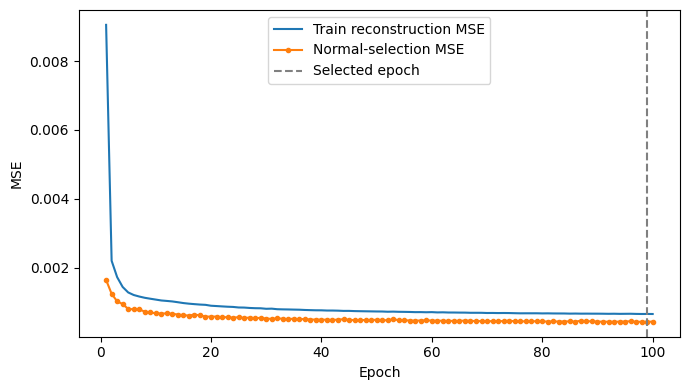

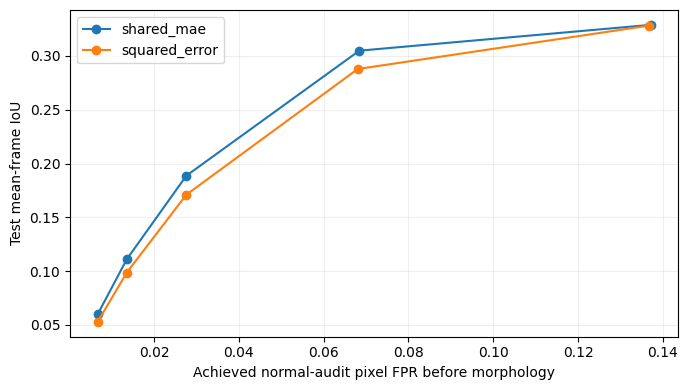

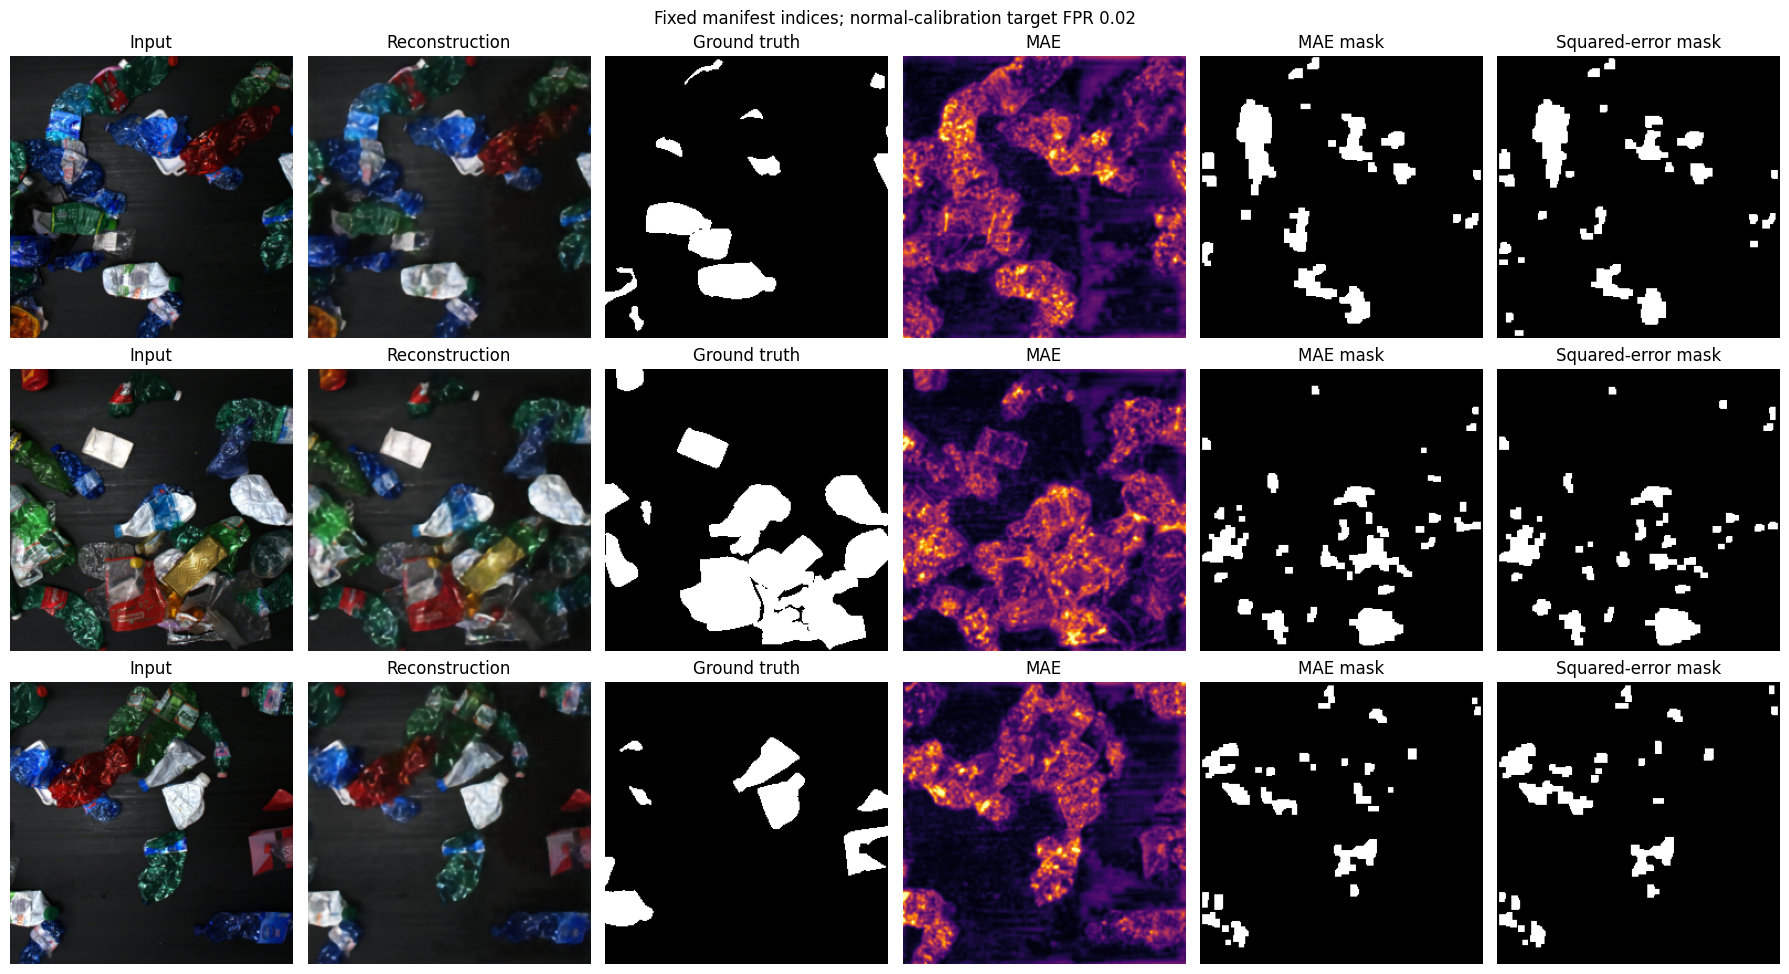

Send compact report and log. Keep full checkpoints for resume:


/kaggle/working/VQVAE2_baseline_3_shared100_report.zip

Completed epochs: 100 selected: 99 steps: 47900


In [8]:
if EVALUATION_COMPLETE:
    history_df=pd.DataFrame(history)
    fig,ax=plt.subplots(figsize=(7,4)); ax.plot(history_df.epoch,history_df.train_mse,label='Train reconstruction MSE')
    ax.plot(history_df.epoch,history_df.select_mse,'o-',label='Normal-selection MSE',markersize=3)
    ax.axvline(best_epoch,color='gray',linestyle='--',label='Selected epoch')
    ax.set(xlabel='Epoch',ylabel='MSE'); ax.legend(); fig.tight_layout()
    fig.savefig(RUN/'training_curve.png',dpi=150); plt.show()
    fig,ax=plt.subplots(figsize=(7,4))
    for s in SCORES:
        d=summary[(summary.score==s)&(summary.processing=='postprocessed')&(summary.protocol!='historical')].sort_values('audit_raw_fpr')
        ax.plot(d.audit_raw_fpr,d.mean_frame_iou,'o-',label=s)
    ax.set(xlabel='Achieved normal-audit pixel FPR before morphology',ylabel='Test mean-frame IoU'); ax.legend(); ax.grid(alpha=.2)
    fig.tight_layout(); fig.savefig(RUN/'iou_vs_fpr.png',dpi=150); plt.show()
    indices=np.linspace(0,len(splits['test'])-1,3,dtype=int); data=cache_images('test')
    fig,axes=plt.subplots(3,6,figsize=(18,10))
    for row,i in enumerate(indices):
        rec=reconstruct(model,data[i]); t=thresholds['shared_mae']['fpr_0.02']; t2=thresholds['squared_error']['fpr_0.02']
        panels=[(data[i],'Input',None),(np.clip(rec,0,1),'Reconstruction',None),(gt[i],'Ground truth','gray'),(maps['test']['shared_mae'][i],'MAE','inferno'),(postprocess(maps['test']['shared_mae'][i]>t),'MAE mask','gray'),(postprocess(maps['test']['squared_error'][i]>t2),'Squared-error mask','gray')]
        for col,(a,title,cmap) in enumerate(panels):
            if col==3: axes[row,col].imshow(a,cmap=cmap,vmin=0,vmax=max(2*t,1e-8))
            else: axes[row,col].imshow(a,cmap=cmap)
            axes[row,col].set_title(title); axes[row,col].axis('off')
    fig.suptitle('Fixed manifest indices; normal-calibration target FPR 0.02')
    fig.tight_layout(); fig.savefig(RUN/'fixed_examples.png',dpi=150); plt.show()
    write_json(RUN/'fixed_examples.json',[splits['test'][int(i)]['relative'] for i in indices])
    write_json(RUN/'status.json',dict(status='complete',maximum_epochs=MAX_EPOCHS,
        completed_epochs=completed_epochs,selected_epoch=best_epoch,optimizer_steps=optimizer_steps,
        parameters=PARAMETERS,backprop_updated_parameters=PARAMETERS-EMA_PARAMETERS,
        ema_codebook_parameters=EMA_PARAMETERS,stop_reason=stop_reason,test_evaluated=True))
    try:
        executed='\n\n'.join(get_ipython().history_manager.input_hist_raw)
    except NameError:
        executed=Path(__file__).read_text()
    (RUN/'executed_cells.py').write_text(executed)
    report=report_zip()
    print('Send compact report and log. Keep full checkpoints for resume:')
    display(FileLink(str(report)))
    print('Completed epochs:',completed_epochs,'selected:',best_epoch,'steps:',optimizer_steps)
else:
    report_zip()
    print('Run paused before complete evaluation. Resume; no completed test comparison is claimed.')
